In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mustafaelrasheed/country-school/Country Schools.csv


## DATA PRocession

In [4]:
# read the dataset
df = pd.read_csv("/kaggle/input/datasets/mustafaelrasheed/country-school/Country Schools.csv")

In [5]:
# Identify the row and columns
df.shape

(50, 8)

In [6]:
# take a peek from the start of the dataset
df.head()

,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


In [7]:
# take a peek from the end of the dataset
df.tail()

,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
45,EMBU,381.0,248.0,133.0,65.09%,8438.0,496.0,46
46,SAMBURU,146.0,49.0,97.0,33.56%,2891.0,98.0,47
47,TOTAL,21729.0,14629.0,7100.0,67.32%,723618.0,29258.0,48
48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,49
49,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50


In [8]:
# check the Genral information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   SNO                    48 non-null     object 
 1   TOTALSCHOOLS           48 non-null     float64
 2   TotalSchoolsInstalled  48 non-null     float64
 3   SchoolsPending         48 non-null     float64
 4   PercentageInstalled    48 non-null     object 
 5   InstalledLDDs          48 non-null     float64
 6   InstalledTDDs          48 non-null     float64
 7   FID                    50 non-null     int64  
dtypes: float64(5), int64(1), object(2)
memory usage: 3.3+ KB


In [9]:
# Get Ganeral Infromation about numerical data
df.describe()

,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,InstalledLDDs,InstalledTDDs,FID
count,48.000000,48.000000,48.000000,48.00000,48.000000,50.00000
mean,905.375000,609.541667,295.833333,30150.75000,1219.083333,25.50000
std,3079.865641,2078.968965,1009.291416,102851.94788,4157.937929,14.57738
min,93.000000,8.000000,4.000000,606.00000,16.000000,1.00000
25%,271.750000,161.250000,53.250000,6289.00000,322.500000,13.25000
50%,422.500000,314.500000,130.500000,14165.00000,629.000000,25.50000
75%,637.000000,420.250000,247.750000,23215.00000,840.500000,37.75000
max,21729.000000,14629.000000,7100.000000,723618.00000,29258.000000,50.00000


In [10]:
# check null value
df.isnull().sum()

SNO                      2
TOTALSCHOOLS             2
TotalSchoolsInstalled    2
SchoolsPending           2
PercentageInstalled      2
InstalledLDDs            2
InstalledTDDs            2
FID                      0
dtype: int64

## DATA Cleaning

In [11]:
# Checking duplicate data entry
duplicate_count = df.duplicated().sum()
print("Duplicate rows found:", duplicate_count)

Duplicate rows found: 0


In [12]:
# 1. This displays only the rows that have at least one missing value
rows_with_nulls = df[df.isnull().any(axis=1)]
display(rows_with_nulls)

# 2. This drops the missing values and saves it to a new "clean" dataset 
df_clean = df.dropna().copy()

# Verify it worked by checking the shape
print("Original data size:", df.shape)
print("Clean data size:", df_clean.shape)
print("Remaining missing cells:", int(df_clean.isna().sum().sum()))

,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,49
49,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50


Original data size: (50, 8)
Clean data size: (48, 8)
Remaining missing cells: 0


## DATA Reduction

In [13]:
drop_from_features = []

# Check for the row identifier in this specific dataset
if "FID" in df_clean.columns:
    drop_from_features.append("FID")

# Check for the county name identifier
if "SNO" in df_clean.columns:
    drop_from_features.append("SNO")

# Safely drop the identifiers so only numerical measurements remain
df_clean = df_clean.drop(columns=drop_from_features, errors="ignore").copy()

print("Columns remaining for analysis:", df_clean.columns.tolist())

Columns remaining for analysis: ['TOTALSCHOOLS', 'TotalSchoolsInstalled', 'SchoolsPending', 'PercentageInstalled', 'InstalledLDDs', 'InstalledTDDs']


## DATA Transformation

In [14]:
## Transforming the datatype 
df_clean['PercentageInstalled'] = df_clean['PercentageInstalled'].str.replace('%', '').astype(float)


In [16]:
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# --- BEFORE SCALING ---
print("--- DATA BEFORE SCALING ---")
display(df_clean.head())

# Isolate the features
X = df_clean

# Scale the features so large numbers don't overpower percentages
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --- AFTER SCALING ---
print("\n--- DATA AFTER SCALING ---")
# Convert the scaled array back into a DataFrame so it displays nicely like a table
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
display(X_scaled_df.head())

print("\n--- PREPROCESSING COMPLETE ---")
print(f"Usable rows remaining: {len(df_clean)}\n")

--- DATA BEFORE SCALING ---


,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs
0,358.0,37.0,321.0,10.34,3744.0,74.0
1,875.0,552.0,323.0,63.09,22982.0,1104.0
2,498.0,242.0,256.0,48.59,15114.0,484.0
3,1238.0,1200.0,38.0,96.93,42162.0,2400.0
4,159.0,143.0,16.0,89.94,7415.0,286.0



--- DATA AFTER SCALING ---


,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs
0,-0.179608,-0.278311,0.025199,-2.119877,-0.259462,-0.278311
1,-0.009967,-0.027971,0.027201,-0.035562,-0.070437,-0.027971
2,-0.133670,-0.178661,-0.039884,-0.608501,-0.147745,-0.178661
3,0.109143,0.287021,-0.258163,1.301561,0.118018,0.287021
4,-0.244905,-0.226785,-0.280191,1.025364,-0.223392,-0.226785



--- PREPROCESSING COMPLETE ---
Usable rows remaining: 48



## Detecting anomalies

In [17]:
from sklearn.ensemble import IsolationForest
# Initialize and fit the Isolation Forest model
iso_forest = IsolationForest(contamination=0.1, random_state=42) 
df_clean['Anomaly'] = iso_forest.fit_predict(X_scaled)

# Map numeric output (-1 for anomaly, 1 for normal) to readable text
df_clean['Anomaly_Label'] = df_clean['Anomaly'].map({1: 'Normal', -1: 'Anomaly'})

print("--- ANOMALY DETECTION SUMMARY ---")
print(df_clean['Anomaly_Label'].value_counts().to_string())
anomalies = df_clean[df_clean['Anomaly_Label'] == 'Anomaly'][['TOTALSCHOOLS', 'TotalSchoolsInstalled']]
print("\nIdentified Anomalies:\n", anomalies.to_string(index=False), "\n")

--- ANOMALY DETECTION SUMMARY ---
Anomaly_Label
Normal     43
Anomaly     5

Identified Anomalies:
  TOTALSCHOOLS  TotalSchoolsInstalled
        358.0                   37.0
       1238.0                 1200.0
        887.0                  833.0
        880.0                  572.0
      21729.0                14629.0 



## Clustering 

In [20]:
from sklearn.cluster import KMeans
# Initialize and fit K-Means with 3 clusters
features = ['TOTALSCHOOLS', 'TotalSchoolsInstalled', 'SchoolsPending', 
            'PercentageInstalled', 'InstalledLDDs', 'InstalledTDDs']
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_clean['Cluster'] = kmeans.fit_predict(X_scaled)

print("--- CLUSTER ANALYSIS SUMMARY ---")
print("Average Feature Values by Cluster:")
print(df_clean.groupby('Cluster')[features].mean().round(2).to_string(), "\n")

--- CLUSTER ANALYSIS SUMMARY ---
Average Feature Values by Cluster:
         TOTALSCHOOLS  TotalSchoolsInstalled  SchoolsPending  PercentageInstalled  InstalledLDDs  InstalledTDDs
Cluster                                                                                                        
0              488.91                 376.00          112.91                77.22       19074.24         752.00
1            21729.00               14629.00         7100.00                67.32      723618.00       29258.00
2              399.64                 158.64          241.00                32.56        6726.29         317.29 



## Visualizing

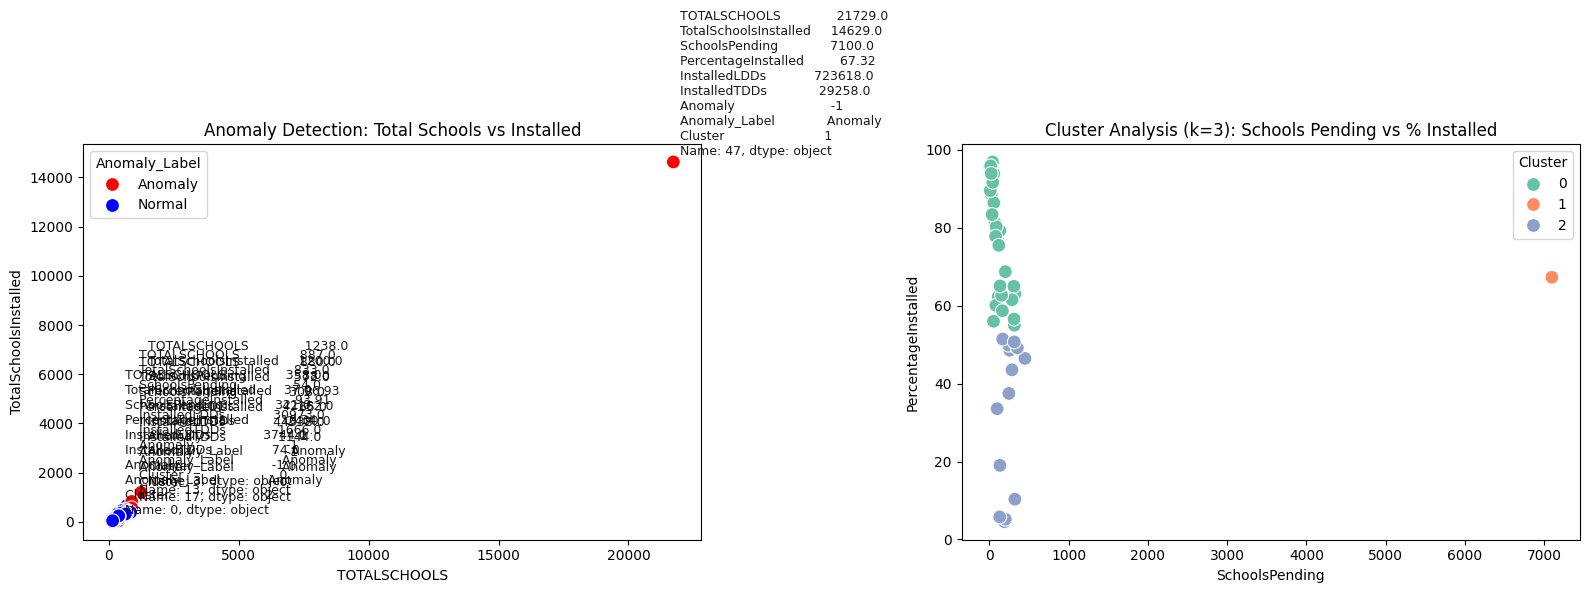

In [23]:
import matplotlib.pyplot as plt

# Set up a 1x2 grid for the plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Anomaly Detection Scatterplot
sns.scatterplot(data=df_clean, x='TOTALSCHOOLS', y='TotalSchoolsInstalled', 
                hue='Anomaly_Label', palette={'Normal': 'blue', 'Anomaly': 'red'}, 
                s=100, ax=axes[0])
axes[0].set_title('Anomaly Detection: Total Schools vs Installed')

# Annotate the names of the anomalous regions on the chart
for i in range(len(df_clean)):
    if df_clean.iloc[i]['Anomaly_Label'] == 'Anomaly':
        axes[0].annotate(df_clean.iloc[i], 
                         (df_clean.iloc[i]['TOTALSCHOOLS'], df_clean.iloc[i]['TotalSchoolsInstalled']),
                         fontsize=9, alpha=0.9, xytext=(5,5), textcoords='offset points')

# Plot 2: Cluster Analysis Scatterplot
sns.scatterplot(data=df_clean, x='SchoolsPending', y='PercentageInstalled', 
                hue='Cluster', palette='Set2', s=100, ax=axes[1])
axes[1].set_title('Cluster Analysis (k=3): Schools Pending vs % Installed')

# Render the plots
plt.tight_layout()
plt.show()